# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Lara Normand  Student ID: B00820883
2. Full name: Amine Benbachir Hassani Student ID: B00821087
3. Full name: Camille Metz  Student ID: B00821603
4. Full name: Tiphaine De Saint Aignan  Student ID: B00819186

**Project role (consultant / data scientist / risk analyst):** Climate risk analyst

**Key quantity (one sentence, with unit):** The 2026 EU ETS carbon cost of the 11 European airline groups in our sample, in % of their revenue, built from their verified ETS emissions (MtCO2, history 2012 to 2025).

**Repo URL:** https://github.com/Lara-Normand-Pro/aidams-lab5-BenbachirHassani-Metz-Normand-DeSaintAignan.git  

## Setup (given)

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False   # our project data are loaded below

# Folders used by this notebook
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [4]:
if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    # EU ETS emissions per airline group and year (from our project pipeline)
    groups = pd.read_csv(DATA_DIR / "ets_by_group.csv")

    # Add up the 11 groups to get one value per year, in million tonnes
    series = groups.groupby("PERIOD_YEAR", as_index=False)["VERIFIED_EMISSIONS"].sum()
    series.columns = ["year", "value"]
    series["value"] = series["value"] / 1e6
    series = series.sort_values("year").reset_index(drop=True)

    NAME, UNIT = "EU ETS emissions of the 11 airline groups", "MtCO2"

print(NAME, "in", UNIT, "from", series.year.min(), "to", series.year.max(), "with", len(series), "years")
series.tail()

EU ETS emissions of the 11 airline groups in MtCO2 from 2012 to 2025 with 14 years


,year,value
9,2021,19.03
10,2022,36.25
11,2023,40.65
12,2024,45.54
13,2025,46.28


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

Our quantity is the EU ETS carbon cost that the 11 airline groups pay in 2026, the first year without free allowances, divided by their revenue. Its history is their verified ETS emissions (46.3 Mt in 2025). An investor or lender uses it to decide which airline groups to underweight or to price with a higher credit spread. Sources of uncertainty: year to year traffic and emissions variation (**A**); the EUA price path, our operator to group mapping and the Air France 2025 imputation (**E**); the price scenario chosen and policy changes such as the proposed 2029 ETS extension or CORSIA rules (**S**).

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [5]:
def fit_predict(train, horizon, model="linear", level=0.90):
    # Data as arrays, log of the values for the loglinear model
    x = train["year"].values.astype(float)
    y = train["value"].values.astype(float)
    if model == "loglinear":
        y = np.log(y)

    # Centre the year for numerical stability
    x_mean = x.mean()
    n = len(x)
    X = np.column_stack([np.ones(n), x - x_mean])

    # OLS fit and residual standard error
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    s = np.sqrt(np.sum(resid**2) / (n - 2))

    # Years to predict
    years = np.arange(int(x.max()) + 1, int(x.max()) + 1 + horizon)
    X0 = np.column_stack([np.ones(horizon), years - x_mean])
    mean = X0 @ beta

    # Prediction interval with the Student t distribution
    leverage = np.sum((X0 @ XtX_inv) * X0, axis=1)
    t_crit = stats.t.ppf(0.5 + level / 2, df=n - 2)
    half = t_crit * s * np.sqrt(1 + leverage)
    lo, hi = mean - half, mean + half

    # Go back to the original scale for the loglinear model
    if model == "loglinear":
        mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)

    return pd.DataFrame({"year": years, "mean": mean, "lo": lo, "hi": hi})


# Hide the last 5 years
H = 5
train = series.iloc[:-H]
test = series.iloc[-H:]

results = []
for m in ["linear", "loglinear"]:
    pred = fit_predict(train, H, model=m)
    pred["model"] = m
    pred["actual"] = test["value"].values
    pred["inside"] = (pred["actual"] >= pred["lo"]) & (pred["actual"] <= pred["hi"])
    results.append(pred)

backtest = pd.concat(results, ignore_index=True)
backtest

,year,mean,lo,hi,model,actual,inside
0,2021,36.45,12.52,60.39,linear,19.03,True
1,2022,36.49,11.16,61.82,linear,36.25,True
2,2023,36.53,9.65,63.42,linear,40.65,True
3,2024,36.58,8.00,65.15,linear,45.54,True
4,2025,36.62,6.24,67.00,linear,46.28,True
5,2021,32.24,15.08,68.92,loglinear,19.03,True
6,2022,31.73,14.20,70.90,loglinear,36.25,True
7,2023,31.23,13.31,73.31,loglinear,40.65,True
8,2024,30.74,12.41,76.13,loglinear,45.54,True
9,2025,30.25,11.54,79.34,loglinear,46.28,True


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

model
linear       5
loglinear    5
Name: inside, dtype: int64


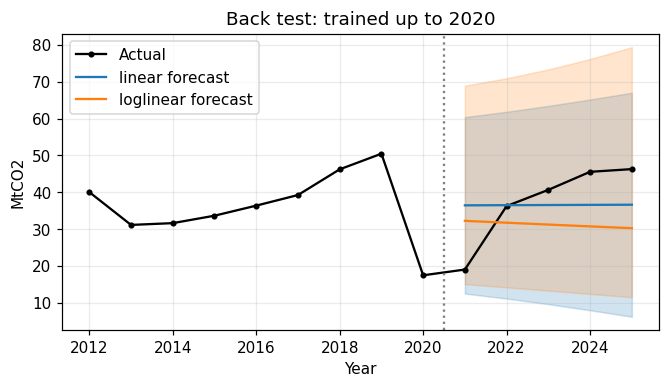

,misses_k,P(X >= k)
0,0,1.00
1,1,0.41
2,2,0.08
3,3,0.01
4,4,0.00
5,5,0.00


In [6]:
# (a) Held out years inside the 90 percent band, per model
print(backtest.groupby("model")["inside"].sum())

# Picture of the back test
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(series.year, series.value, "k.-", label="Actual")
for m, c in [("linear", "tab:blue"), ("loglinear", "tab:orange")]:
    b = backtest[backtest.model == m]
    ax.plot(b.year, b["mean"], color=c, label=m + " forecast")
    ax.fill_between(b.year, b.lo, b.hi, color=c, alpha=0.2)
ax.axvline(train.year.max() + 0.5, color="grey", ls=":")
ax.set_xlabel("Year")
ax.set_ylabel(UNIT)
ax.set_title("Back test: trained up to " + str(train.year.max()))
ax.legend()
plt.show()

# (b) Chance of k or more misses out of 5 if the 90 percent band is right
k = np.arange(0, 6)
pd.DataFrame({"misses_k": k, "P(X >= k)": stats.binom.sf(k - 1, 5, 0.10)})

**Your answer (Q2):**

(a) Linear: **5 of 5** held out years inside the 90% band. Loglinear: **5 of 5** inside.

(b) For X ~ Bin(5, 0.1): P(X ≥ 1) = 0.41, P(X ≥ 2) = 0.08, P(X ≥ 3) = 0.01. So **2 misses** would make us doubt the band and 3 would reject it.

(c) The perfect coverage is misleading. The 2020 COVID drop inflates the residuals, so the bands run from about 6 to 80 Mt and say almost nothing. The point forecasts are also wrong: the linear model predicts 36.6 Mt for 2025 against 46.3 Mt actual, and the loglinear model even predicts a decline (30.3 Mt). The rolling back test also gives 100% coverage, but with only 2 to 4 test points per horizon. We keep the linear model only as a reference and do not use either trend for the fan chart. The gap between the two models shows that the trend shape cannot be identified from this short and broken series.

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [7]:
# Rolling origin: fit on all past years, predict 1, 2 and 3 years ahead
rolling = []
for i in range(9, len(series) - 1):  # cutoff from the 10th year onwards
    past = series.iloc[: i + 1]
    for m in ["linear", "loglinear"]:
        pred = fit_predict(past, 3, model=m)
        pred["h"] = [1, 2, 3]
        pred["model"] = m
        rolling.append(pred)

# Keep only the years we can check against the data
rolling = pd.concat(rolling).merge(series, on="year")
rolling["inside"] = (rolling["value"] >= rolling["lo"]) & (rolling["value"] <= rolling["hi"])

print("Coverage by horizon (share of years inside the 90 percent band):")
print(rolling.pivot_table(index="h", columns="model", values="inside", aggfunc="mean").round(2))
print("Number of test points per horizon and model:")
print(rolling.pivot_table(index="h", columns="model", values="inside", aggfunc="count"))

Coverage by horizon (share of years inside the 90 percent band):
model  linear  loglinear
h                       
1        1.00       1.00
2        1.00       1.00
3        1.00       1.00
Number of test points per horizon and model:
model  linear  loglinear
h                       
1           4          4
2           3          3
3           2          2


---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [8]:
N = 5_000
TARGET_YEAR = 2026

# Fixed inputs from our data
E_2025 = series.loc[series.year == 2025, "value"].item()  # MtCO2 in 2025
fin = pd.read_csv(DATA_DIR / "airline_financials.csv")
REVENUE = fin["revenue_eur_m"].sum()  # EUR million, latest fiscal year, 11 groups
print("Emissions 2025:", round(E_2025, 1), "Mt   Revenue:", round(REVENUE), "EUR million")


def compute_quantity(growth, price):
    # Emissions in 2026, all paid because free allowances end in 2026
    emissions = E_2025 * (1 + growth)
    # Mt times EUR per tonne gives EUR million
    cost = emissions * price
    # ETS carbon cost in percent of revenue
    return 100 * cost / REVENUE


# Input 1: emissions growth from 2025 to 2026, Normal with mean 2 percent and sd 3 points
growth = rng.normal(0.02, 0.03, N)

# Input 2: EUA price in EUR per tonne, Triangular with our low, central and high values
price = rng.triangular(70, 90, 130, N)

q = compute_quantity(growth, price)
q_lo, q_med, q_hi = np.percentile(q, [5, 50, 95])
print(f"{TARGET_YEAR} ETS cost: median {q_med:.2f} percent of revenue, 90 percent interval [{q_lo:.2f}, {q_hi:.2f}]")
print(f"In EUR billion: median {q_med * REVENUE / 100 / 1000:.2f}, interval [{q_lo * REVENUE / 100 / 1000:.2f}, {q_hi * REVENUE / 100 / 1000:.2f}]")


# One at a time sensitivity: fix one input at its median
def rel_half_width(x):
    lo, med, hi = np.percentile(x, [5, 50, 95])
    return (hi - lo) / 2 / med


sens = pd.DataFrame({
    "case": ["both inputs uncertain", "growth fixed", "price fixed"],
    "rel_half_width": [
        rel_half_width(q),
        rel_half_width(compute_quantity(np.median(growth), price)),
        rel_half_width(compute_quantity(growth, np.median(price))),
    ],
})
sens

Emissions 2025: 46.3 Mt   Revenue: 155131 EUR million
2026 ETS cost: median 2.90 percent of revenue, 90 percent interval [2.35, 3.65]
In EUR billion: median 4.50, interval [3.65, 5.66]


,case,rel_half_width
0,both inputs uncertain,0.22
1,growth fixed,0.22
2,price fixed,0.05


**Input distributions (justification).**

*Emissions growth 2025 to 2026 ~ Normal(2%, 3 points).* Growth slowed to 1.6% in 2025 after the post-COVID rebound (+12% in both 2023 and 2024); before COVID it ran at 6 to 9% a year in most years (2015-2019). The rebound is over, so we centre on 2%, close to the latest observed year. A 3-point standard deviation gives a 90% range of about -3% to +7%, which covers a mild downturn as well as a partial return to pre-COVID growth.

*EUA price ~ Triangular(70, 90, 130) EUR/t.* The three points are the low, central and high prices of our project scenarios. The values come from our project definition (24 September): EUR 70 is the bottom of the 2026 traded EUA range (about EUR 70 to 87), EUR 90 assumes moderate cap tightening, and EUR 130 reflects a tight market towards 2030, within the USD 50 to 150 range suggested in the course for the risk analyst role. The range is asymmetric (+40 / -20 EUR/t) because our high scenario sits further from the central case than the low one. Note that this distribution **blends the three scenarios** into one prior (its median is about EUR 95, not 90). Part D treats them separately, and the headline figure in Q6 uses the central scenario of Part D.

### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

(a) With the price drawn from a distribution that blends our three scenarios (triangular 70/90/130, median about EUR 95), the 2026 ETS cost has a median of **2.90% of revenue** (EUR 4.5 bn) and a 90% interval of **[2.35%, 3.65%]** (EUR 3.7 to 5.7 bn). For the central EUR 90 scenario alone (Part D) the median is 2.74% with a 90% interval of [2.28%, 3.22%].

(b) Fixing the **EUA price** cuts the relative half width from 0.22 to 0.05, while fixing growth leaves it at 0.22. The price is **epistemic**: we do not know the market path, and it is partly a scenario choice.

(c) We would collect EUA futures prices for December 2026 and recent analyst forecasts to narrow the price distribution, which would remove most of the range. What remains is the **aleatoric** variation in traffic and emissions (about ±5%), which no data can remove before the year happens.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [9]:
# Our three EUA price scenarios from the project definition
# Inside each scenario the price still moves by about 10 percent
SCENARIOS = {"Low (EUR 70)": 70, "Central (EUR 90)": 90, "High (EUR 130)": 130}

rows = []
for name, p in SCENARIOS.items():
    g = rng.normal(0.02, 0.03, N)
    pr = rng.normal(p, 0.10 * p, N)
    x = compute_quantity(g, pr)
    lo, med, hi = np.percentile(x, [5, 50, 95])
    rows.append({"scenario": name, "median": med, "lo_5": lo, "hi_95": hi, "width_90": hi - lo})

scen = pd.DataFrame(rows)

# Largest gap between scenario medians versus width inside one scenario
gap = scen["median"].max() - scen["median"].min()
print(f"Largest gap between medians: {gap:.2f} points")
print(f"Width of the central 90 percent interval: {scen.loc[1, 'width_90']:.2f} points")
scen

Largest gap between medians: 1.80 points
Width of the central 90 percent interval: 0.95 points


,scenario,median,lo_5,hi_95,width_90
0,Low (EUR 70),2.14,1.77,2.51,0.73
1,Central (EUR 90),2.74,2.28,3.22,0.95
2,High (EUR 130),3.94,3.27,4.65,1.38


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

The largest gap between scenario medians is **1.80 points** (2.14% in the low scenario against 3.94% in the high one). This is almost twice the **0.95 point** width of the central 90% interval, and larger than the widest interval (1.38 points in the high scenario). The scenarios barely overlap, so the price assumption matters more than the noise inside a scenario. We will show **one band per scenario** and not one fan mixing them, so readers see that the result depends on a market and policy question rather than on forecasting error.

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [10]:
# Optional part, not done here.
# Our financial inputs (revenue, EBIT, Scope 1) were collected from annual reports
# and are logged with their source in data airline_financials.csv

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

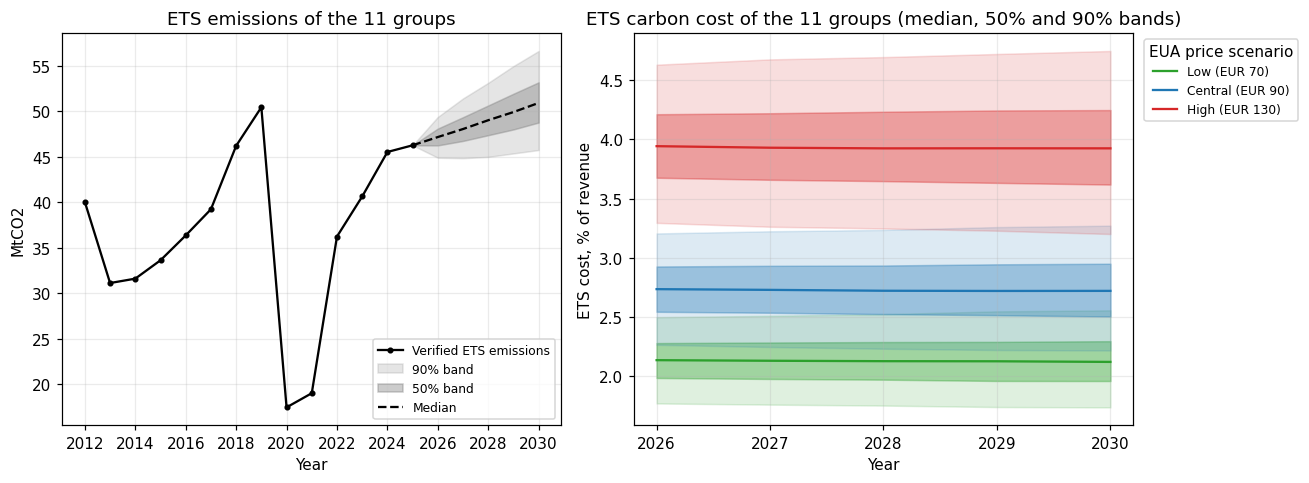

In [11]:
YEARS_AHEAD = np.arange(2026, 2031)
colors = ["tab:green", "tab:blue", "tab:red"]

# Emission paths to 2030: each year a new growth draw
paths = np.zeros((N, len(YEARS_AHEAD)))
level = np.full(N, E_2025)
for j in range(len(YEARS_AHEAD)):
    level = level * (1 + rng.normal(0.02, 0.03, N))
    paths[:, j] = level

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel 1: emissions history and fan to 2030
ax1.plot(series.year, series.value, "k.-", label="Verified ETS emissions")
x = np.r_[2025, YEARS_AHEAD]
p5, p25, p50, p75, p95 = np.percentile(paths, [5, 25, 50, 75, 95], axis=0)
ax1.fill_between(x, np.r_[E_2025, p5], np.r_[E_2025, p95], color="grey", alpha=0.2, label="90% band")
ax1.fill_between(x, np.r_[E_2025, p25], np.r_[E_2025, p75], color="grey", alpha=0.4, label="50% band")
ax1.plot(x, np.r_[E_2025, p50], color="k", ls="--", label="Median")
ax1.set_xticks(range(2012, 2031, 2))
ax1.set_xlabel("Year")
ax1.set_ylabel("MtCO2")
ax1.set_title("ETS emissions of the 11 groups")
ax1.legend(loc="lower right", fontsize=8)

# Panel 2: ETS cost in percent of revenue, one fan per price scenario
# From 2027 revenue grows at the expected traffic rate (2 percent a year, the mean of the growth draws).
# 2026 keeps the latest revenue so it matches Parts C and D.
# Holding it at its latest value would make the ratio drift up only because emissions grow.
REV_GROWTH = 0.02
rev_path = REVENUE * (1 + REV_GROWTH) ** (YEARS_AHEAD - 2026)
for (name, p), c in zip(SCENARIOS.items(), colors):
    prices = rng.normal(p, 0.10 * p, (N, 1))
    expo = 100 * paths * prices / rev_path
    e5, e25, e50, e75, e95 = np.percentile(expo, [5, 25, 50, 75, 95], axis=0)
    ax2.fill_between(YEARS_AHEAD, e5, e95, color=c, alpha=0.15)
    ax2.fill_between(YEARS_AHEAD, e25, e75, color=c, alpha=0.35)
    ax2.plot(YEARS_AHEAD, e50, color=c, label=name)
ax2.set_xlabel("Year")
ax2.set_ylabel("ETS cost, % of revenue")
ax2.set_title("ETS carbon cost of the 11 groups (median, 50% and 90% bands)")
ax2.set_xticks(YEARS_AHEAD)
ax2.legend(title="EUA price scenario", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig_uncertainty.png", dpi=200, bbox_inches="tight")
plt.show()

**Note on the fan chart.** 2026 uses the latest revenue, as in Parts C and D. From 2027, revenue grows at 2% a year, the expected traffic growth used for emissions. The cost ratio's median is therefore roughly flat from 2026 to 2030 and its bands widen only through emissions uncertainty around that rate. Fare pass-through and changes in revenue per passenger are not modelled.

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.



**Your answer (Q6):**

Under full auctioning and a central EUA price of EUR 90/t, the 11 airline groups face an EU ETS cost of 2.7% of revenue in 2026 (median; 90% interval 2.3% to 3.2%). A 2021-2025 back test kept all 5 held-out years inside the 90% band, but only because the COVID drop widened it; the trend forecasts were biased low and are not used. The EUA price drives the range: fixing it cuts the relative half width from 22% to 5%. The EUR 70 and EUR 130 scenarios give medians of 2.1% and 3.9%, a gap wider than any single interval. Even at EUR 70, the cost is very likely above 1.7% of revenue. Limitations: revenue is held at its latest level for 2026 and fare pass through is not modelled, the ETS covers only intra-EEA flights while revenue is group-wide, and CORSIA is excluded.

In [12]:
# Group-level ETS bill at the high scenario (EUR 130/t), 2025 verified emissions
g25 = groups[groups.PERIOD_YEAR == 2025][["group", "VERIFIED_EMISSIONS"]]
by_group = g25.merge(fin[["group", "revenue_eur_m", "ebit_eur_m"]], on="group")
by_group["cost_eur_m"] = by_group["VERIFIED_EMISSIONS"] / 1e6 * 130
by_group["pct_revenue"] = 100 * by_group["cost_eur_m"] / by_group["revenue_eur_m"]
by_group["pct_ebit"] = 100 * by_group["cost_eur_m"] / by_group["ebit_eur_m"]
by_group.sort_values("pct_revenue", ascending=False).round(1)

,group,VERIFIED_EMISSIONS,revenue_eur_m,ebit_eur_m,cost_eur_m,pct_revenue,pct_ebit
6,Ryanair,"12,607,232.00","15,544.30","2,374.20","1,638.90",10.50,69.00
5,Norwegian,"2,031,578.00","2,568.00",269.60,264.10,10.30,98.00
0,Aegean,"1,137,724.00","1,859.70",218.20,147.90,8.00,67.80
9,Wizz Air,"3,308,971.00","5,691.40",139.70,430.20,7.60,307.90
7,SAS,"1,992,625.00","4,437.10",273.80,259.00,5.80,94.60
2,Finnair,"1,216,313.00","3,106.20",64.20,158.10,5.10,246.30
10,easyJet,"4,183,879.00","11,794.10",812.30,543.90,4.60,67.00
8,TAP,"1,110,967.00","4,313.00",243.40,144.40,3.30,59.30
4,Lufthansa Group,"7,944,374.00","39,597.00","2,030.00","1,032.80",2.60,50.90
1,Air France-KLM,"5,488,945.00","33,007.00","2,002.00",713.60,2.20,35.60


### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q7):**


"Because the range is this wide, the decision that changes is which carbon price lenders stress test at: at EUR 130, Ryanair’s ETS bill eats about two thirds of its operating profit and Wizz Air’s more than all of it, so airline credit should be priced on the high scenario."